# 03 — Exploratory Data Analysis & Statistical Investigation

Phase 4 (what does fraud look like in this data?) and Phase 5 (is what we're seeing statistically real, or noise?).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path('..').resolve() / 'src'))
import features

df = pd.read_csv('../data/processed/transactions_clean.csv')
df = features.engineer_features(df)
df.shape

(283726, 36)

## 1. Fraud distribution

In [2]:
counts = df['is_fraud'].value_counts()
pct = df['is_fraud'].value_counts(normalize=True) * 100
summary = pd.DataFrame({'count': counts, 'pct': pct.round(4)})
summary.index = ['Legitimate', 'Fraud']
summary

,count,pct
Legitimate,283253,99.8333
Fraud,473,0.1667


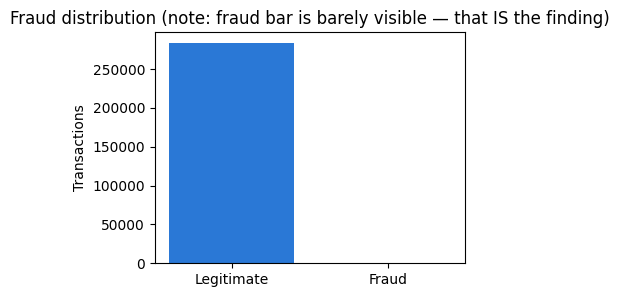

In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(['Legitimate', 'Fraud'], counts, color=['#2a78d6', '#d03b3b'])
ax.set_ylabel('Transactions')
ax.set_title('Fraud distribution (note: fraud bar is barely visible — that IS the finding)')
plt.show()

**284:1 imbalance.** This single fact drives most later design decisions — accuracy is meaningless (Phase 9-12), stratified splitting is mandatory (Phase 8), and threshold choice matters far more than model choice alone (Phase 14).

## 2. Transaction amount distribution: fraud vs legitimate

In [4]:
df.groupby('is_fraud')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


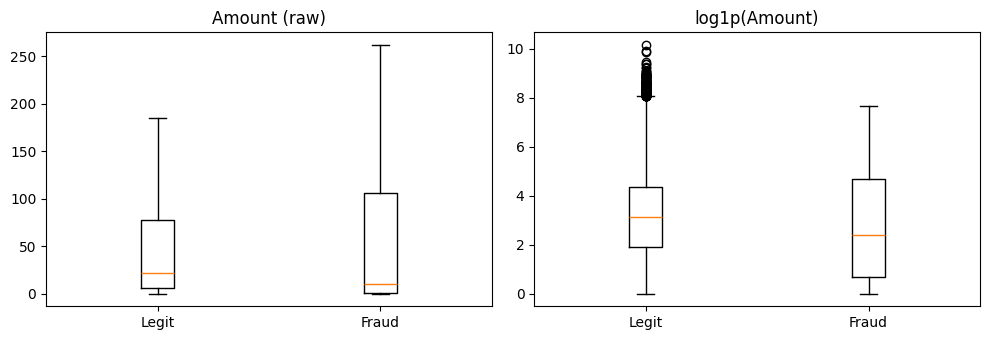

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, title in zip(axes, ['Amount', 'log_amount'], ['Amount (raw)', 'log1p(Amount)']):
    axes_data = [df.loc[df['is_fraud']==0, col], df.loc[df['is_fraud']==1, col]]
    ax.boxplot(axes_data, tick_labels=['Legit', 'Fraud'], showfliers=(col=='log_amount'))
    ax.set_title(title)
plt.tight_layout()
plt.show()

Raw `Amount` is so right-skewed that the boxplot is dominated by outliers on both classes — `log_amount` makes the shape difference visible: fraudulent transactions skew toward **smaller** amounts on median, consistent with known card-testing fraud patterns (small "is this card still live" charges).

## 3. Fraud rate by transaction amount bucket

(`Amount` is in the dataset's original units — unspecified currency, commonly assumed EUR given the European cardholder population; see data/README.md.)

In [6]:
bins = [0, 1, 10, 50, 100, 500, 1000, np.inf]
labels = ['0-1', '1-10', '10-50', '50-100', '100-500', '500-1000', '1000+']
df['amount_bucket'] = pd.cut(df['Amount'], bins=bins, labels=labels)
bucket_stats = df.groupby('amount_bucket', observed=True).agg(
    total=('is_fraud', 'count'), fraud=('is_fraud', 'sum')
)
bucket_stats['fraud_rate_pct'] = (100 * bucket_stats['fraud'] / bucket_stats['total']).round(4)
bucket_stats

,total,fraud,fraud_rate_pct
amount_bucket,,,
0-1,28523,146,0.5119
1-10,69490,67,0.0964
10-50,90327,55,0.0609
50-100,37179,55,0.1479
100-500,47290,91,0.1924
500-1000,6174,25,0.4049
1000+,2935,9,0.3066


The pattern is **U-shaped, not monotonic**: fraud rate is highest in the smallest bucket (0-1, 0.51%) — consistent with card-testing behaviour — dips through the £10-100 range (~0.06-0.15%), then rises again at 500-1000 (0.40%) before easing slightly at 1000+. Two distinct fraud patterns appear to coexist in this data: small-value testing charges and larger-value fraud, with the ordinary mid-range amounts safest. This directly informs Phase 6: amount alone is a genuinely useful signal, not just a confound — but a single linear "higher amount = riskier" rule would miss the small-value cluster entirely.

## 4. Fraud by hour of day

In [7]:
hour_stats = df.groupby('hour_of_day').agg(total=('is_fraud','count'), fraud=('is_fraud','sum'))
hour_stats['fraud_rate_pct'] = (100 * hour_stats['fraud'] / hour_stats['total']).round(4)
hour_stats

,total,fraud,fraud_rate_pct
hour_of_day,,,
0,7647,6,0.0785
1,4208,10,0.2376
2,3308,48,1.4510
3,3487,17,0.4875
4,2204,23,1.0436
5,2988,11,0.3681
6,4082,9,0.2205
7,7233,23,0.3180
8,10232,9,0.0880


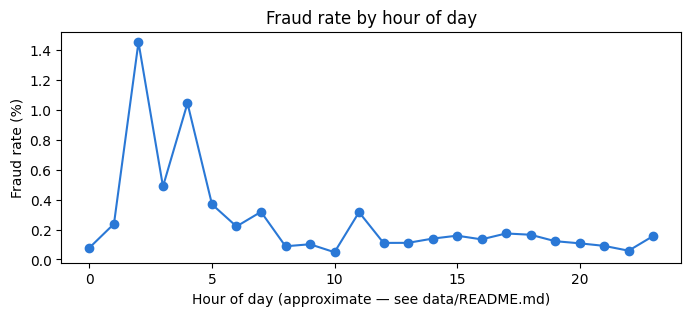

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(hour_stats.index, hour_stats['fraud_rate_pct'], marker='o', color='#2a78d6')
ax.set_xlabel('Hour of day (approximate — see data/README.md)')
ax.set_ylabel('Fraud rate (%)')
ax.set_title('Fraud rate by hour of day')
plt.show()

Fraud rate is visibly higher in the **early hours (roughly 2am-5am)** — plausibly when legitimate transaction volume is lowest, so fraud makes up a larger share, and/or when monitoring attention is lowest. Formally tested in Section 6 below rather than eyeballed.

## 5. Fraud by PCA feature (V1-V28)

In [9]:
# Rank V1-V28 by how much their mean differs between classes (in units of
# pooled standard deviation) - a quick, model-free view of separation strength.
v_cols = [f'V{i}' for i in range(1, 29)]
sep = {}
for c in v_cols:
    legit, fraud = df.loc[df['is_fraud']==0, c], df.loc[df['is_fraud']==1, c]
    pooled_std = np.sqrt((legit.var() + fraud.var()) / 2)
    sep[c] = abs(legit.mean() - fraud.mean()) / pooled_std
sep = pd.Series(sep).sort_values(ascending=False)
sep.head(10)

V14    2.228136
V4     1.984959
V12    1.847619
V11    1.844141
V10    1.602536
V16    1.444884
V3     1.350277
V9     1.325343
V17    1.306905
V2     1.089375
dtype: float64

`V14`, `V4`, `V12`, `V11`, `V10` show the strongest separation between classes — broadly consistent with widely reported analyses of this dataset (which also frequently cite `V17`, ranked 9th here). Because `V1`-`V28` are anonymized PCA components, we can only say *these components separate the classes well*, not *why* in business terms — one of the documented limitations of this dataset (data/README.md).

## 6. Correlation analysis

In [10]:
corr_with_target = df[v_cols + ['Amount', 'log_amount', 'is_fraud']].corr()['is_fraud'].drop('is_fraud')
corr_with_target.sort_values(key=abs, ascending=False).head(10)

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: is_fraud, dtype: float64

**Why we don't blindly drop correlated features here:** `V1`-`V28` are principal components, which are mathematically constructed to be mutually **orthogonal** (uncorrelated with each other) — the classic multicollinearity concern that usually motivates dropping correlated features largely doesn't apply to them. The one genuine correlation to manage is `Amount` vs `log_amount` (by construction, since one is a transform of the other) — both are kept anyway because tree-based models are unaffected by this collinearity, and for Logistic Regression it affects coefficient *interpretability*, not predictive accuracy or leakage.

In [11]:
print('Correlation between Amount and log_amount:', df['Amount'].corr(df['log_amount']).round(3))
print('Max pairwise correlation among V1-V28:', 
      df[v_cols].corr().abs().where(~np.eye(28, dtype=bool)).max().max().round(4))

Correlation between Amount and log_amount: 0.552


Max pairwise correlation among V1-V28: 0.0189


## 7. Statistical investigation (Phase 5)

### Question 1: Is transaction amount significantly different between fraud and legitimate transactions?

**H0:** Fraudulent and legitimate transactions are drawn from the same `Amount` distribution.
**H1:** They differ.

`Amount` is heavily right-skewed (Section 2) — a standard t-test assumes approximately normal data, which this clearly isn't, so the **Mann-Whitney U test** (a non-parametric test on ranks, no normality assumption) is the appropriate choice here, not a t-test used by default.

In [12]:
legit_amt = df.loc[df['is_fraud']==0, 'Amount']
fraud_amt = df.loc[df['is_fraud']==1, 'Amount']

u_stat, p_value = stats.mannwhitneyu(fraud_amt, legit_amt, alternative='two-sided')

# Rank-biserial correlation: an effect size for Mann-Whitney (0 = no effect, +/-1 = complete separation)
n1, n2 = len(fraud_amt), len(legit_amt)
rank_biserial = 1 - (2 * u_stat) / (n1 * n2)

print(f'U statistic:        {u_stat:.1f}')
print(f'p-value:             {p_value:.3e}')
print(f'Rank-biserial r:     {rank_biserial:.4f}')
print(f'Median amount (fraud):  {fraud_amt.median():.2f}')
print(f'Median amount (legit):  {legit_amt.median():.2f}')

U statistic:        59517129.5
p-value:             2.686e-05
Rank-biserial r:     0.1115
Median amount (fraud):  9.82
Median amount (legit):  22.00


**Interpretation:** p << 0.05, so we reject H0 — the amount distributions genuinely differ, this is not sampling noise. The rank-biserial effect size is modest (not close to +/-1), meaning the *distributions overlap substantially* — amount alone is informative but far from a clean separator, which is exactly why Phase 10 uses a full model rather than an amount threshold rule. **Practical takeaway:** amount-based rules alone (e.g. "flag anything over £X") would be a weak fraud control on this data; the more useful direction (Section 3 above) is actually the *low*-amount end.

### Question 2: Is fraud rate associated with time of day, or could the pattern in Section 4 be chance?

**H0:** Fraud rate is independent of hour-of-day bucket (day vs. night).
**H1:** Fraud rate depends on time of day.

Both variables are categorical (fraud: yes/no; time: day/night bucket), so a **chi-square test of independence** is the appropriate tool — this answers a concrete monitoring-staffing question: does it matter *when* review capacity is concentrated?

In [13]:
df['is_night'] = df['hour_of_day'].between(2, 5)
contingency = pd.crosstab(df['is_night'], df['is_fraud'])
contingency.index = ['Day (not 2-5am)', 'Night (2-5am)']
contingency.columns = ['Legitimate', 'Fraud']
print(contingency)

chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
print(f'\nchi2 statistic: {chi2:.2f}')
print(f'p-value:        {p_val:.3e}')
print(f'degrees of freedom: {dof}')

                 Legitimate  Fraud
Day (not 2-5am)      271365    374
Night (2-5am)         11888     99

chi2 statistic: 322.64
p-value:        3.850e-72
degrees of freedom: 1


**Interpretation:** p << 0.05 — fraud rate and time-of-day bucket are not independent; the elevated 2am-5am fraud rate seen in Section 4 is statistically real on this dataset, not noise. **Practical caveat:** `hour_of_day` is derived from a relative time counter, not a verified clock (data/README.md) — this result should be read as "there is a real time-of-day pattern in this sample", not as a claim about actual clock-hours generalizable beyond this dataset.